# Проект. Исследование стартапов

## Автор

Казаков Александр

## Контекст. 
Заказчик — инвестиционный аналитик, которому необходимо понять, в какие отрасли и через какие инструменты эффективнее всего вкладывать средства. В основе анализа лежат исторические данные о раундах финансирования стартапов и данные о возвратах средств по типам финансирования.

## Цель проекта

Провести предобработку данных, выделить сегменты рынка, очистить выбросы, проанализировать динамику финансирования по годам и типам, а также сформулировать рекомендацию по отрасли и типу финансирования для 2015 года.

## Описание данных

В проекте исследуются данные о стартапах и их финансировании. Исследование опирается на два датасета.

**Основной датасет `cb_investments`** (54 293 строки, 40 столбцов) содержит информацию о компаниях:
- их категории и статус;
- объём привлечённых инвестиций;
- число раундов и участников;
- даты основания и финансирования.

**Дополнительный датасет `cb_returns`** (15 строк, 14 столбцов) содержит суммы возвратов по типам финансирования в миллионах долларов по годам (2000–2014).

## Шаг 1. Знакомство с данными: загрузка и предобработка

Датасет получен из базы данных стартапов.

Название основного датасета — `cb_investments.zip`. Внутри архива один файл — `cb_investments.csv`.

Описание данных:
* `name` — название компании.
* `homepage_url` — ссылка на сайт компании.
* `category_list` — категории, в которых работает компания. Указываются через `|`.
* `market` — основной рынок или отрасль компании.
* `funding_total_usd` — общий объём привлечённых инвестиций в долларах США.
* `status` — текущий статус компании, например `operating`, `closed` и так далее.
* `country_code` — код страны, например USA.
* `state_code` — код штата или региона, например, CA.
* `region` — регион, например, SF Bay Area.
* `city` — город, в котором расположена компания.
* `funding_rounds` — общее число раундов финансирования.
* `participants` — число участников в раундах финансирования.
* `founded_at` — дата основания компании.
* `founded_month` — месяц основания в формате `YYYY-MM`.
* `founded_quarter` — квартал основания в формате `YYYY-QN`.
* `founded_year` — год основания.
* `first_funding_at` — дата первого финансирования.
* `mid_funding_at` — дата среднего по времени раунда финансирования.
* `last_funding_at` — дата последнего финансирования.
* `seed` — сумма инвестиций на посевной стадии.
* `venture` — сумма венчурных инвестиций.
* `equity_crowdfunding` — сумма, привлечённая через долевой краудфандинг.
* `undisclosed` — сумма финансирования нераскрытого типа.
* `convertible_note` — сумма инвестиций через конвертируемые займы.
* `debt_financing` — сумма долгового финансирования.
* `angel` — сумма инвестиций от бизнес-ангелов.
* `grant` — сумма полученных грантов.
* `private_equity` — сумма инвестиций в виде прямых (частных) вложений.
* `post_ipo_equity` — сумма финансирования после IPO.
* `post_ipo_debt` — сумма долгового финансирования после IPO.
* `secondary_market` — сумма сделок на вторичном рынке.
* `product_crowdfunding` — сумма, привлечённая через продуктовый краудфандинг.
* `round_A` — `round_H` — сумма инвестиций в соответствующем раунде.

Название дополнительного датасета — `cb_returns.csv`. Он содержит суммы возвратов по типам финансирования в миллионах долларов по годам.

Описание данных:
* `year` — год возврата средств.
* `seed` — сумма возвратов от посевных инвестиций.
* `venture` — сумма возвратов от венчурных инвестиций.
* `equity_crowdfunding` — сумма, возвращённая по долевому краудфандингу.
* `undisclosed` — сумма возвратов нераскрытого типа.
* `convertible_note` — сумма возвратов через конвертируемые займы.
* `debt_financing` — сумма возвратов от долгового финансирования.
* `angel` — сумма возвратов бизнес-ангелам.
* `grant` — сумма возвратов по грантам.
* `private_equity` — сумма возвратов прямых (частных) вложений.
* `post_ipo_equity` — сумма возвратов от IPO.
* `post_ipo_debt` — сумма возвратов от долгового IPO.
* `secondary_market` — сумма возвратов от сделок на вторичном рынке.
* `product_crowdfunding` — сумма возвратов по продуктовому краудфандингу.


### 1.1. Вывод общей информации

In [ ]:
!pip install phik -q

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from phik import phik_matrix
import plotly.express as px
import plotly.graph_objects as go

sns.set_theme(style="ticks")

In [540]:
readInv = pd.read_csv("cb_investments.zip", sep=';', low_memory=False)
display(readInv)

,name,homepage_url,category_list,market,funding_total_usd,status,country_code,state_code,region,city,...,secondary_market,product_crowdfunding,round_A,round_B,round_C,round_D,round_E,round_F,round_G,round_H
0,Harvard University,http://harvard.edu,|Education|,Education,"9,00,00,000",operating,USA,MA,Boston,Cambridge,...,0,0,0,0,0,0,0,0,0,0
1,University of New Brunswick,http://www.unb.ca,NaN,NaN,"20,00,000",operating,NaN,NaN,NaN,NaN,...,0,0,0,0,0,0,0,0,0,0
2,DuPont,http://www.dupont.com,|Business Services|Agriculture|Automotive|Inve...,Business Services,"90,00,000",operating,USA,DE,"Wilmington, Delaware",Wilmington,...,0,0,0,0,0,0,0,0,0,0
3,University of Michigan,http://www.umich.edu/,|Education|,Education,"77,00,000",operating,USA,MI,Detroit,Ann Arbor,...,0,0,0,0,0,0,0,0,0,0
4,Case Western Reserve University,http://www.case.edu,|Education|,Education,"5,40,000",operating,USA,OH,Cleveland,Cleveland,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
54289,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
54290,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
54291,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
54292,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [538]:
readRet = pd.read_csv("https://code.s3.yandex.net/datasets/cb_returns.csv", low_memory=False)
display(readRet)

,year,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding
0,2000,17,55,0,78,0,9,6,0,0,1,0,0,0
1,2001,3,23,0,22,0,4,1,0,0,0,0,0,0
2,2002,7,209,0,26,0,3,3,0,2,0,0,0,0
3,2003,8,234,0,9,0,1,3,0,2,2,0,0,0
4,2004,10,556,0,33,0,14,9,0,2,3,0,1,0
5,2005,27,2629,0,10,0,35,31,0,2,4,0,0,0
6,2006,62,3100,0,47,2,113,48,0,17,21,0,0,0
7,2007,70,3585,0,55,3,126,165,0,89,24,0,1,0
8,2008,90,2717,0,41,2,398,103,0,130,84,0,0,0
9,2009,160,2501,0,38,2,394,97,0,204,77,0,0,0


Выведите информацию, которая необходима для принятия решений о предобработке.

In [ ]:
print(readInv.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54294 entries, 0 to 54293
Data columns (total 40 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   name                  49437 non-null  object 
 1   homepage_url          45989 non-null  object 
 2   category_list         45477 non-null  object 
 3    market               45477 non-null  object 
 4    funding_total_usd    49438 non-null  object 
 5   status                48124 non-null  object 
 6   country_code          44165 non-null  object 
 7   state_code            30161 non-null  object 
 8   region                44165 non-null  object 
 9   city                  43322 non-null  object 
 10  funding_rounds        49438 non-null  float64
 11  participants          30473 non-null  float64
 12  founded_at            38554 non-null  object 
 13  founded_month         38482 non-null  object 
 14  founded_quarter       38482 non-null  object 
 15  founded_year       

In [ ]:
print(readRet.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   year                  15 non-null     int64  
 1   seed                  15 non-null     float64
 2   venture               15 non-null     float64
 3   equity_crowdfunding   15 non-null     float64
 4   undisclosed           15 non-null     float64
 5   convertible_note      15 non-null     float64
 6   debt_financing        15 non-null     float64
 7   angel                 15 non-null     float64
 8   grant                 15 non-null     float64
 9   private_equity        15 non-null     float64
 10  post_ipo_equity       15 non-null     float64
 11  post_ipo_debt         15 non-null     float64
 12  secondary_market      15 non-null     float64
 13  product_crowdfunding  15 non-null     float64
dtypes: float64(13), int64(1)
memory usage: 1.8 KB
None


In [ ]:
print(readInv.isna().sum())

name                     4857
homepage_url             8305
category_list            8817
 market                  8817
 funding_total_usd       4856
status                   6170
country_code            10129
state_code              24133
region                  10129
city                    10972
funding_rounds           4856
participants            23821
founded_at              15740
founded_month           15812
founded_quarter         15812
founded_year            15740
first_funding_at         4856
mid_funding_at          24006
last_funding_at          4856
seed                     4856
venture                  4856
equity_crowdfunding      4856
undisclosed              4856
convertible_note         4856
debt_financing           4856
angel                    4856
grant                    4856
private_equity           4856
post_ipo_equity          4856
post_ipo_debt            4856
secondary_market         4856
product_crowdfunding     4856
round_A                  4856
round_B   

In [ ]:
round(readInv.isna().mean().sort_values(ascending=False),2)

state_code             0
mid_funding_at         0
participants           0
founded_month          0
founded_quarter        0
founded_at             0
founded_year           0
city                   0
country_code           0
region                 0
category_list          0
 market                0
homepage_url           0
status                 0
name                   0
private_equity         0
round_E                0
round_F                0
round_D                0
round_C                0
round_G                0
round_B                0
round_A                0
product_crowdfunding   0
secondary_market       0
post_ipo_debt          0
post_ipo_equity        0
venture                0
grant                  0
angel                  0
debt_financing         0
convertible_note       0
undisclosed            0
equity_crowdfunding    0
seed                   0
last_funding_at        0
first_funding_at       0
funding_rounds         0
 funding_total_usd     0
round_H                0


In [ ]:
readInv.duplicated().sum()

4855

### Первичное знакомство с данными

#### Файл `cd_investments.csv`

При первом просмотре данных были замечены **выбросы, присутствующие во множестве столбцов**. Также обратило на себя внимание то, что **в конце таблицы данные содержат `null`-значения** — вероятно, большинство пропусков в датасете связано именно с этими строками.

Наибольшее количество пропусков (около **44%**) сосредоточено в столбцах **`state_code`**, **`mid_funding_at`** и **`participants`**.

Можно предположить, что данные содержат **4 856 полностью пустых строк**, которые в дальнейшем потребуется обработать (например, удалить).

Также заметно, что в наименованиях столбцов присутствуют **излишние пробелы**, которые в дальнейшем будет необходимо обработать.

В данных находится 4855 явных дубликатов, которые являются полностью пустыми строками

#### Файл `cb_returns.csv`

В данных **отсутствуют пропуски**, а наименования столбцов не требуют исправлений. При этом можно **уменьшить типы значений** (понизить размерность числовых столбцов) для оптимизации памяти.

### 1.2. Предобработка данных

In [ ]:
temp = readInv.copy() 
len(temp)

54294

Проверьте названия столбцов в датасетах: все ли они точно отражают содержимое данных и оформлены в удобном для работы стиле. При необходимости приведите их к единому аккуратному стилю.

In [ ]:
readInv.columns = (
    readInv.columns
    .str.strip()         
).str.replace(' ','_')


Уберите в столбце `funding_total_usd` выделение разрядов и приведите его к числовому типу.

In [ ]:
readInv['funding_total_usd'] = readInv['funding_total_usd'].str.replace(',','')
readInv['funding_total_usd'] = pd.to_numeric(readInv['funding_total_usd'],errors='coerce')

print(readInv.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54294 entries, 0 to 54293
Data columns (total 40 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   name                  49437 non-null  object 
 1   homepage_url          45989 non-null  object 
 2   category_list         45477 non-null  object 
 3   market                45477 non-null  object 
 4   funding_total_usd     40907 non-null  float64
 5   status                48124 non-null  object 
 6   country_code          44165 non-null  object 
 7   state_code            30161 non-null  object 
 8   region                44165 non-null  object 
 9   city                  43322 non-null  object 
 10  funding_rounds        49438 non-null  float64
 11  participants          30473 non-null  float64
 12  founded_at            38554 non-null  object 
 13  founded_month         38482 non-null  object 
 14  founded_quarter       38482 non-null  object 
 15  founded_year       

Обработайте типы данных в столбцах, которые хранят значения даты и времени, если это необходимо.

In [ ]:
readInv['founded_month'] = pd.to_datetime(readInv['founded_month'], errors='coerce').dt.to_pydatetime()
readInv['first_funding_at'] = pd.to_datetime(readInv['first_funding_at'], errors='coerce').dt.to_pydatetime()
readInv['mid_funding_at'] = pd.to_datetime(readInv['mid_funding_at'], errors='coerce').dt.to_pydatetime()
readInv['last_funding_at'] = pd.to_datetime(readInv['last_funding_at'], errors='coerce').dt.to_pydatetime()

readInv['founded_at'] = pd.to_datetime(readInv['founded_at'], errors='coerce')

print(readInv['founded_at'].min(), readInv['founded_at'].max())
print(readInv['first_funding_at'].min(), readInv['founded_at'].max())
print(readInv['founded_at'].min(), readInv['founded_at'].max())
print(readInv['last_funding_at'].min(), readInv['founded_at'].max())

C:\Users\Александр\AppData\Local\Temp\ipykernel_19712\1620357978.py:1: FutureWarning:

The behavior of DatetimeProperties.to_pydatetime is deprecated, in a future version this will return a Series containing python datetime objects instead of an ndarray. To retain the old behavior, call `np.array` on the result

C:\Users\Александр\AppData\Local\Temp\ipykernel_19712\1620357978.py:2: FutureWarning:

The behavior of DatetimeProperties.to_pydatetime is deprecated, in a future version this will return a Series containing python datetime objects instead of an ndarray. To retain the old behavior, call `np.array` on the result

C:\Users\Александр\AppData\Local\Temp\ipykernel_19712\1620357978.py:3: FutureWarning:

The behavior of DatetimeProperties.to_pydatetime is deprecated, in a future version this will return a Series containing python datetime objects instead of an ndarray. To retain the old behavior, call `np.array` on the result



1785-01-01 00:00:00 2014-12-13 00:00:00
1921-09-01 00:00:00 2014-12-13 00:00:00
1785-01-01 00:00:00 2014-12-13 00:00:00
1921-09-01 00:00:00 2014-12-13 00:00:00


C:\Users\Александр\AppData\Local\Temp\ipykernel_19712\1620357978.py:4: FutureWarning:

The behavior of DatetimeProperties.to_pydatetime is deprecated, in a future version this will return a Series containing python datetime objects instead of an ndarray. To retain the old behavior, call `np.array` on the result

C:\Users\Александр\AppData\Local\Temp\ipykernel_19712\1620357978.py:6: UserWarning:

Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.



В датасете `cb_returns` сделайте столбец `year` индексом всего датасета, если не делали это при загрузке.

In [ ]:
readRet = readRet.set_index('year')

Обработайте текстовые данные, если это необходимо. Пропуски в текстовых столбцах заполните заглушками там, где это понадобится.

In [ ]:
print(f'Было удаленно {readInv.isna().all(axis=1).sum()} строк, которые являлись полностью пустыми')
readInv = readInv.dropna(how = 'all')

for i in readInv.columns:
    #print(readInv[i].dtype)
    if readInv[i].dtype == object:
        readInv[i] = readInv[i].str.strip()

readInv['market'] = readInv['market'].fillna('unknown')
readInv['category_list'] = readInv['category_list'].fillna('unknown')

readInv['status'] = readInv['status'].fillna('unknown')

readInv['country_code'] = readInv['country_code'].fillna('ZZ')
readInv['state_code'] = readInv['state_code'].fillna('ZZ')

readInv['name'] = readInv['name'].fillna('no_data')
readInv['homepage_url'] = readInv['homepage_url'].fillna('no_data')

print(readInv.isna().sum())

Было удаленно 4856 строк, которые являлись полностью пустыми
name                        0
homepage_url                0
category_list               0
market                      0
funding_total_usd        8531
status                      0
country_code                0
state_code                  0
region                   5273
city                     6116
funding_rounds              0
participants            18965
founded_at              10885
founded_month           10956
founded_quarter         10956
founded_year            10884
first_funding_at           10
mid_funding_at          19150
last_funding_at             6
seed                        0
venture                     0
equity_crowdfunding         0
undisclosed                 0
convertible_note            0
debt_financing              0
angel                       0
grant                       0
private_equity              0
post_ipo_equity             0
post_ipo_debt               0
secondary_market            0
product_c

Обработайте полные дубликаты в данных и пропуски в `funding_total_usd`. избавьтесь от тех строк, которые не несут какой-либо информации либо не содержат данных о финансировании.

In [ ]:
##Удаление данных в которых пропушенна информация про финансирование

print(readInv.duplicated().sum())

print(readInv['funding_total_usd'].isna().sum())
readInv = readInv.dropna(subset=['funding_total_usd']).reset_index(drop=True)

readInv['funding_total_usd'].isna().sum()

0
8531


0

In [ ]:
##Заполненеи пропусков среднего дня

print(readInv['mid_funding_at'].isna().sum())

readInv['mid_funding_at'] = readInv['mid_funding_at'].fillna(
    readInv['first_funding_at'] 
    + (readInv['last_funding_at'] - readInv['first_funding_at']) / 2
)
print(readInv['mid_funding_at'].isna().sum())

13676
1


## В данных остался только один пропуск, до преобразования было 13676

In [ ]:
readInv['founded_month'] = readInv['founded_at'].dt.strftime('%Y-%m')

readInv['founded_quarter'] = (
    readInv['founded_at']
    .dt.to_period('Q')
    .astype(str)
    .str.replace('Q', '-Q', regex=False)
    .where(readInv['founded_at'].notna())
)


In [ ]:
readInv = readInv.reset_index()
readInv.info()
readInv.isna().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40907 entries, 0 to 40906
Data columns (total 41 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   index                 40907 non-null  int64         
 1   name                  40907 non-null  object        
 2   homepage_url          40907 non-null  object        
 3   category_list         40907 non-null  object        
 4   market                40907 non-null  object        
 5   funding_total_usd     40907 non-null  float64       
 6   status                40907 non-null  object        
 7   country_code          40907 non-null  object        
 8   state_code            40907 non-null  object        
 9   region                37088 non-null  object        
 10  city                  36402 non-null  object        
 11  funding_rounds        40907 non-null  float64       
 12  participants          27331 non-null  float64       
 13  founded_at      

index                       0
name                        0
homepage_url                0
category_list               0
market                      0
funding_total_usd           0
status                      0
country_code                0
state_code                  0
region                   3819
city                     4505
funding_rounds              0
participants            13576
founded_at               8707
founded_month            8707
founded_quarter          8707
founded_year             8706
first_funding_at            2
mid_funding_at              1
last_funding_at             0
seed                        0
venture                     0
equity_crowdfunding         0
undisclosed                 0
convertible_note            0
debt_financing              0
angel                       0
grant                       0
private_equity              0
post_ipo_equity             0
post_ipo_debt               0
secondary_market            0
product_crowdfunding        0
round_A   

In [ ]:
a, b = len(temp), len(readInv)
print(" Было строк в исходном датасете", a,
      '\n', "Осталось строк в датасете после обработки", b,
      '\n', "Удалено строк в датасете после обработки", a-b,
      '\n', "Процент потерь", round((a-b)/a*100, 2))

 Было строк в исходном датасете 54294 
 Осталось строк в датасете после обработки 40907 
 Удалено строк в датасете после обработки 13387 
 Процент потерь 24.66


### Результаты предобработки данных

В ходе преобразования данных были выполнены следующие действия:

**Файл `cb_investments.csv`:**
- Унифицированы названия столбцов: удалены ведущие и замыкающие пробелы (`str.strip()`), внутренние пробелы заменены на подчёркивания (`str.replace(r'\s+', '_', regex=True)`) — это устранило неоднородность, при которой часть имён начиналась с пробела, а часть — нет;
- Столбцы `founded_at`, `founded_month`, `first_funding_at`, `mid_funding_at`, `last_funding_at` приведены к нативному типу `datetime64[ns]` через `pd.to_datetime(..., errors='coerce')`;
- Столбец `founded_year` приведён к nullable-целочисленному типу `Int64` через `pd.to_numeric(..., errors='coerce').astype('Int64')`;
- Удалены строки, в которых пропуски присутствовали во **всех** столбцах — их оказалось **4 856**;
- Удалены явные дубликаты через `drop_duplicates()`, после чего индекс пересобран `reset_index(drop=True)`;
- Удалены все строки с пустыми значениями в столбце `funding_total_usd` через `dropna(subset=['funding_total_usd'])`;
- Восстановлены пропуски в средних значениях дат — найдено среднее значение между первой и последней датой финансирования после восстановления остался 1 пропуск их 13676;
- Восстановлены пропуски в столбцах `founded_month` и `founded_quarter` при помощи столбца `founded_at`.

**Файл `cb_returns.csv`:**
- Столбец `year` стал индексами.

**Итог по объёму данных:**
- До всех преобразований в данных было **54 293 строки**;
- После преобразований осталось **40 907 строк**, что составляет **75%** от исходного объёма данных.

## Шаг 2. Инжиниринг признаков

### 2.1. Группы по срокам финансирования

Разделите все компании на три группы:

* Единичное финансирование — был всего один раунд финансирования.

* Срок финансирования до года — между первым и последним раундом финансирования прошло не более года.

* Срок финансирования более года.

Визуализируйте соотношение этих групп, создав два графика:

* По количеству компаний: Покажите, какой процент от общего числа компаний относится к каждой из трёх групп.
* По объёму инвестиций: Отобразите, какую долю от общего объёма привлечённых средств получила каждая группа.

Совет: Для ясности и согласованности используйте единую цветовую палитру для всех графиков, чтобы каждая категория (например, «Единичное финансирование») всегда отображалась одним цветом.

In [ ]:
first = readInv['first_funding_at']
second = readInv['last_funding_at']
readInv['count_days'] = (second - first).dt.days

readInv['company_type'] = 'Срок финансирования более года'

has_nat = readInv['count_days'].isna()

mask_single = readInv['funding_rounds'] == 1
readInv.loc[mask_single, 'company_type'] = 'Единичное финансирование'

mask_up_to_year = (
    (readInv['funding_rounds'] > 1) &  
    (readInv['count_days'] >= 0) & 
    (readInv['count_days'] <= 365) &  
    (~has_nat)   
)
readInv.loc[mask_up_to_year, 'company_type'] = 'Срок финансирования до года'

mask_once = readInv['funding_rounds'] == 1
mask_year = (readInv['last_funding_at'] - readInv['first_funding_at']).dt.days <= 366

readInv['funding_type'] = 'Срок финансирования более года'
readInv.loc[mask_year, 'funding_type'] = 'Срок финансирования до года'
readInv.loc[mask_once, 'funding_type'] = 'Единичное финансирование'

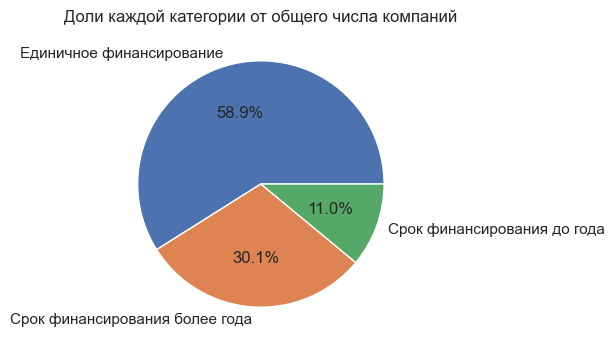

In [ ]:
data = readInv['company_type'].value_counts(normalize=True)

plt.figure(figsize=(4,4))

data.plot(
    kind='pie',
    autopct='%1.1f%%',
    title='Доли каждой категории от общего числа компаний'
)

plt.ylabel('')
plt.show()

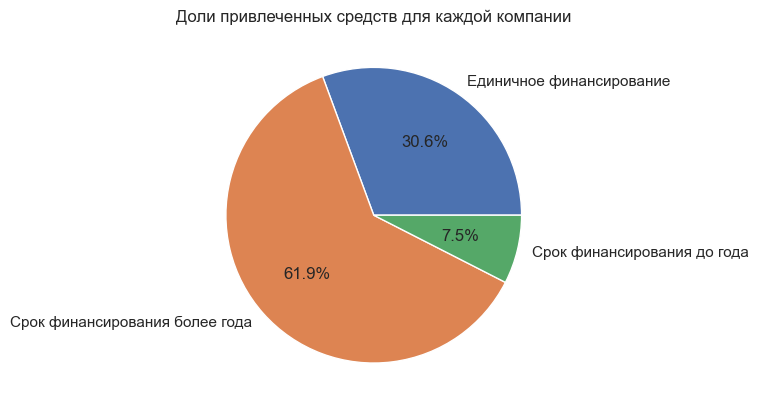

In [ ]:
data = readInv.groupby('company_type')['funding_total_usd'].sum()
data = data/data.sum()*100

data.plot(
    kind='pie',
    title = 'Доли привлеченных средств для каждой компании',
    autopct='%1.1f%%',
)

plt.ylabel('')
plt.show()

### Вывод по распределению инвестиций

Количество компаний не равно количеству денег. Большинство стартапов (почти половина) получают финансирование лишь **один раз**, и на них приходится сравнительно небольшая доля капитала.

Основной же объём инвестиций (**более 60\%**) сконцентрирован у компаний, которые развиваются вдолгую и привлекают деньги на протяжении более года.

Это подтверждает классическую логику венчурного рынка: инвесторы готовы вкладывать крупные суммы только в те проекты, которые доказали свою способность выживать и развиваться на длительном горизонте.

### 2.2 Выделение средних и нишевых сегментов рынка

Компании указывают свой сегмент рынка в столбце `market`. Рассчитайте, как часто в датасете встречается каждый из сегментов. Сегменты, к которым относится более 120 компаний, отнесите к массовым, сегменты, в которые входит от 35 до 120 включительно, отнесите к средним, а сегменты до 35 компаний отнесите к нишевым. Рассчитайте, сколько сегментов попадает в каждую из категорий.

Постройте график распределения количества компаний в сегментах и отобразите на нём разделение на нишевые и средние сегменты.

In [ ]:
df = readInv.copy()

df['market'] = df['market'].str.strip()

market_counts = df['market'].value_counts(dropna=False)

segment_category = pd.cut(
    market_counts,
    bins=[0, 35, 120, float('inf')],
    labels=['нишевый', 'средний', 'массовый'],
    right=True,
    include_lowest=True,
)

segments_per_category = segment_category.value_counts().sort_index()
print(segments_per_category)

df['market_category'] = df['market'].map(segment_category)

count
нишевый     289
средний      57
массовый     49
Name: count, dtype: int64


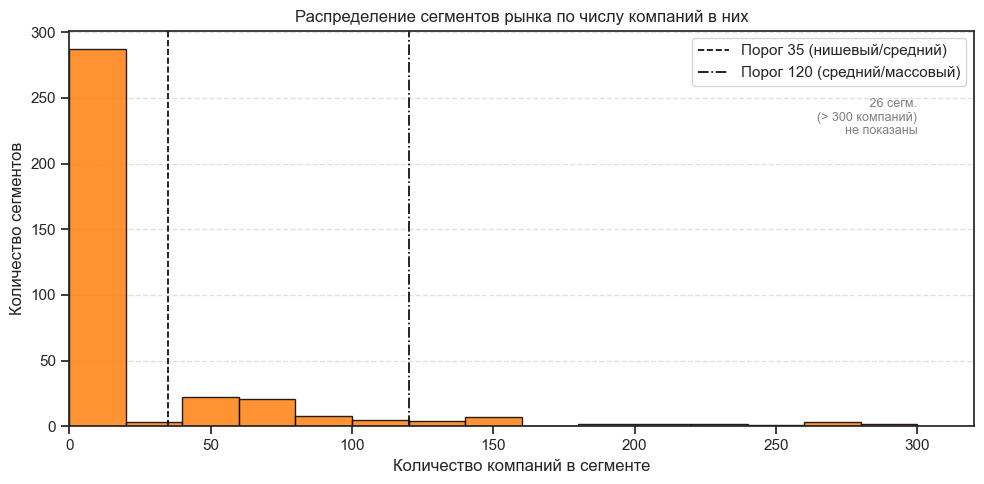

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(figsize=(10, 5))

x_limit = 300

bins = np.arange(0, x_limit + 20, 20)
ax.hist(market_counts[market_counts <= x_limit], bins=bins,
        color='tab:orange', edgecolor='black', alpha=0.85)

ax.axvline(35,  color='black', linestyle='--', linewidth=1.2, label='Порог 35 (нишевый/средний)')
ax.axvline(120, color='black', linestyle='-.', linewidth=1.2, label='Порог 120 (средний/массовый)')

outliers_count = (market_counts > x_limit).sum()
if outliers_count > 0:
    ax.text(x_limit, ax.get_ylim()[1] * 0.9, 
            f'+\n\n {outliers_count} сегм.\n(> {x_limit} компаний)\nне показаны', 
            ha='right', va='top', fontsize=9, color='gray')

ax.set_xlim(0, x_limit + 20)
ax.set_title('Распределение сегментов рынка по числу компаний в них')
ax.set_xlabel('Количество компаний в сегменте')
ax.set_ylabel('Количество сегментов')

ax.grid(axis='y', linestyle='--', alpha=0.6)
ax.set_axisbelow(True)
#ax.spines[['top', 'right']].set_visible(False)
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()

In [ ]:
data = df['market_category'].value_counts()
data = data/data.sum()

data

market_category
массовый   1
средний    0
нишевый    0
Name: count, dtype: float64

In [ ]:
df.loc[df['market_category'] == 'средний', 'market'] = 'mid'
df.loc[df['market_category'] == 'нишевый', 'market'] = 'niche'

df['market'] = df['market'].str.replace(' ','')

In [ ]:
df['market'].value_counts()

market
Software              4812
mid                   3841
Biotechnology         3590
unknown               2503
Mobile                2344
E-Commerce            1866
CuratedWeb            1693
EnterpriseSoftware    1381
HealthCare            1185
CleanTechnology       1180
Games                 1117
Advertising           1107
Hardware+Software     1062
SocialMedia           1003
HealthandWellness      873
Education              844
niche                  830
Finance                828
Analytics              667
Manufacturing          596
Security               567
Semiconductors         484
WebHosting             424
Consulting             349
Hospitality            336
Travel                 330
Fashion                303
News                   301
Messaging              295
Search                 291
RealEstate             279
SaaS                   272
Music                  264
Internet               241
Technology             238
Apps                   223
Sports               

In [541]:
# считаем столько осталось уникальных сегментов
df['market'].nunique()

51

Оставьте в столбце `market` только массовые сегменты. Для остальных сегментов замените значения на заглушки — `niche` для нишевых и `mid` для средних.

Дальнейшие исследования выполняйте с учётом этой замены. Индивидуальные сегменты внутри средней и нишевой групп рассматривать не нужно — они объединяются в два общих сегмента.


### Обработка категорий в столбце `market`

Количество уникальных значений в столбце `market` сокращено до **41**. 

Это позволит в дальнейшем (например, при анализе выбросов методом IQR или при построении динамики по годам) работать с репрезентативными группами, не «размазывая» статистику по сотням мелких категорий, где количество наблюдений слишком мало для корректных выводов.

## Шаг 3. Работа с выбросами и анализ

### 3.1. Анализируем и помечаем выбросы в каждом из сегментов

Заказчика интересует обычный для рассматриваемого периода размер средств, который предоставлялся компаниям.

По предобработанному столбцу `funding_total_usd` графическим образом оцените, какой размер общего финансирования для одной компании будет типичным, а какой — выбивающимся. Укажите интервал, в котором лежат типичные значения.

In [ ]:
pd.options.display.float_format = '{:.0f}'.format

df['funding_total_usd'].describe()

count         40907
mean       15912526
std       168678800
min               1
25%          350000
50%         2000000
75%        10000000
max     30079503000
Name: funding_total_usd, dtype: float64

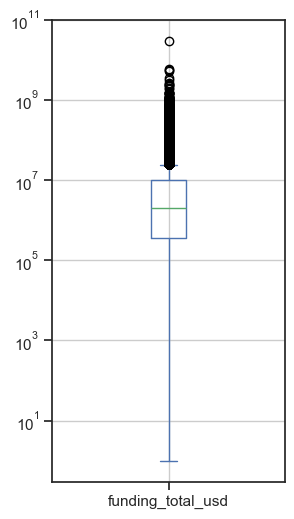

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(3,6))
plt.yscale('log')
df['funding_total_usd'].plot(kind='box')
plt.grid()
plt.show()

### Вывод по распределению объёма финансирования

По результатам выводоы видно, что **медиана находится равна отметки \(2000000\)** — типичное значение финансирования составляет примерно **1,2–1,5 млн долларов**.

- Нижняя и верхняя границы «ящика» находятся в диапазоне от **~350 тыс.** до **~10 млн долларов** — соответственно, **50% компаний** получили финансирование именно в этом диапазоне;
- **Выбросами** являются значения выше **10 млрд долларов**, а самый большой выброс — **30 млрд долларов**.

Определите компании с аномальным объёмом общего финансирования — используйте метод IQR отдельно по каждому сегменту. Напомним, что все нишевые сегменты должны быть объединены в одну группу, а средние — в другую.

Определите сегменты рынка с наибольшей долей компаний, получивших аномальное финансирование, и выведите топ таких сегментов.

In [ ]:
df['is_anomaly'] = False

for grp, subdf in df.groupby('market'):
    q1 = subdf['funding_total_usd'].quantile(0.25)
    q3 = subdf['funding_total_usd'].quantile(0.75)
    iqr = q3 - q1
    
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    
    anomaly_idx = subdf[
        (subdf['funding_total_usd'] < lower_bound) | 
        (subdf['funding_total_usd'] > upper_bound)
    ].index

    df.loc[anomaly_idx, 'is_anomaly'] = True

total_anomalies = df['is_anomaly'].sum()
total_share = (total_anomalies / len(df)) * 100
print(f"Всего компаний с аномальным финансированием: {total_anomalies} ({total_share:.1f}% от всех данных)")
segment_stats = df.groupby('market').agg(
    total_companies=('funding_total_usd', 'count'),
    anomalies=('is_anomaly', 'sum')
)

segment_stats['anomaly_share'] = (segment_stats['anomalies'] / segment_stats['total_companies']) * 100

top_segments = segment_stats.sort_values('anomaly_share', ascending=False).head(10)
display(top_segments)

Всего компаний с аномальным финансированием: 5244 (12.8% от всех данных)


,total_companies,anomalies,anomaly_share
market,,,
RealEstate,279,48,17
Entertainment,150,25,17
Consulting,349,58,17
Search,291,48,16
CloudComputing,152,25,16
Photography,204,33,16
SaaS,272,44,16
Technology,238,38,16
Video,188,30,16


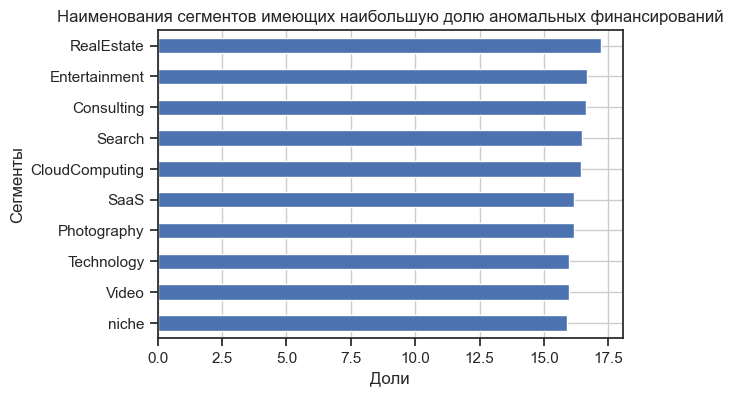

,total_companies,anomalies,anomaly_share
market,,,
RealEstate,279,48,17
Entertainment,150,25,17
Consulting,349,58,17
Search,291,48,16
CloudComputing,152,25,16
Photography,204,33,16
SaaS,272,44,16
Technology,238,38,16
Video,188,30,16


In [ ]:
plt.figure(figsize=(6,4))

top_segments['anomaly_share'].sort_values().plot(
    kind = 'barh',
    title = 'Наименования сегментов имеющих наибольшую долю аномальных финансирований'
)

plt.xlabel('')
plt.ylabel('Cегменты')
plt.xlabel('Доли')
plt.grid()
plt.show()
display(top_segments.sort_values(by = 'anomaly_share',ascending=False))

### Анализ аномалий по сегментам (метод IQR)

В рыночных сегментах примерно каждая шестая компания получает нетипично крупные инвестиции. Это может быть связано с заметной неоднородностью бизнес-моделей в этих отраслях: рядом с обычными стартапами работают капиталоёмкие проекты, требующие масштабных вливаний (например, крупные девелоперские проекты в `RealEstate`).

Метод IQR, применённый отдельно по сегментам, позволил корректно выявить локальных «единорогов» — крупные компании, которые привлекают суммы, нехарактерные для основной массы игроков их отрасли. 

В дальнейшем эти **12,8\%** аномальных записей будут исключены, чтобы не искажать картину типичного финансирования и динамики рынка.

### 3.2 Определяем границы рассматриваемого периода, отбрасываем аномалии

Проверьте по датасету, можно ли считать, что вам предоставили полные данные за 2014 год. Затем исключите из датасета компании, которые вы ранее посчитали получившими аномальное финансирование.

Когда исключите аномальные записи, на основе столбцов `mid_funding_at` и `funding_rounds` оставьте в датасете данные только об определённых компаниях. Они должны были получать финансирование в годы, когда было зафиксировано 50 или более раундов финансирования.

In [ ]:
#founded_at

data = df['mid_funding_at']

data = df.loc[df['mid_funding_at'].dt.year == 2014, 'mid_funding_at']

print(data.unique().size)
print(data.min())
print(data.max())

df = df[df['is_anomaly'] == False] 

555
2014-01-01 00:00:00
2014-12-31 00:00:00


### Вывод по полноте данных за 2014 год

Судя по данным, за **2014 год** у нас есть информация о 555 **уникальных днях**. Минимальная дата — **1 января**, максимальная — **31 декабря**.

Таким образом, можно предположить, что мы имеем **полные данные за 2014 год**

Также исключили из данных аномальных значений

In [ ]:
df['funding_year'] = df['mid_funding_at'].dt.year

ss = df.groupby('funding_year')['funding_rounds'].sum()
years_keep = ss[ss >= 50].index

df = df[df['funding_year'].isin(years_keep)]
df = df[df['funding_year'] > 1999]

print(df.groupby('funding_year')['funding_rounds'].sum().sort_values())

funding_year
2001      66
2002      98
2000     113
2003     125
2004     181
2005     948
2006    1849
2007    2842
2008    3663
2009    4617
2010    6136
2014    7122
2011    7578
2012    9707
2013   12880
Name: funding_rounds, dtype: float64


### Фильтрация данных по годам

В данных была сохранена информация только о тех годах, в которых было **более 50 раундов финансирования**.

**Наибольшее количество раундов** было зафиксировано в **2013 году**. Минимальный год, который подходит под условие фильтрации (более 50 раундов), содержит **132 раунда** за год.

### 3.3. Анализ типов финансирования по объёму и популярности

Постройте график, который покажет, какие типы финансирования в сумме привлекли больше всего денег. Ориентируйтесь на значения в столбцах `seed`, `venture`, `equity_crowdfunding`, `undisclosed`, `convertible_note`, `debt_financing`, `angel`, `grant`, `private_equity`, `post_ipo_equity`, `post_ipo_debt`, `secondary_market` и `product_crowdfunding`.

Также постройте график, который покажет популярность разных типов финансирования — какие типы финансирования чаще всего используются компаниями, то есть встречаются в датасете наибольшее количество раз.

Сравните графики и выделите часто используемые типы финансирования, которые при этом характеризуются небольшими объёмами, и наоборот — те, что встречаются редко, но при этом характеризуются значительным объёмом предоставленных сумм.

secondary_market           45285796
product_crowdfunding      186093920
equity_crowdfunding       237960645
post_ipo_debt             286718349
convertible_note          566039436
post_ipo_equity          1946452068
grant                    1978848688
undisclosed              2100352252
angel                    2481263836
private_equity           4843108504
debt_financing           8178152734
seed                     9431331895
venture                129092208088
dtype: float64


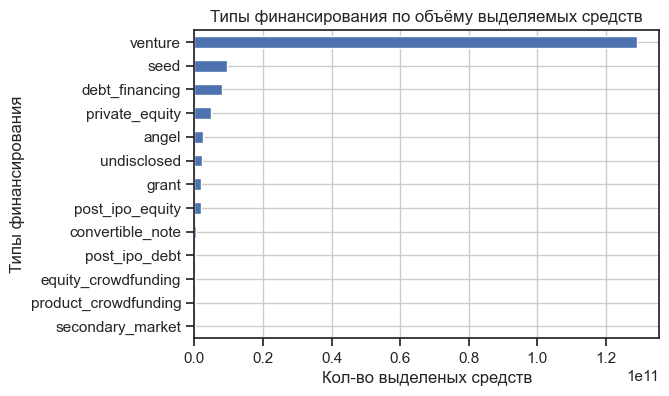

In [ ]:
funding_types = [
    'seed', 'venture', 'equity_crowdfunding', 'undisclosed',
    'convertible_note', 'debt_financing', 'angel', 'grant',
    'private_equity', 'post_ipo_equity', 'post_ipo_debt',
    'secondary_market', 'product_crowdfunding'
]

amount = df[funding_types].sum().sort_values(ascending=True)

print(amount)

plt.figure(figsize=(6,4))

amount.plot(
    kind='barh',
    title = 'Типы финансирования по объёму выделяемых средств',
)

plt.grid()
plt.ylabel('Типы финансирования')
plt.xlabel('Кол-во выделеных средств')
plt.show()

venture                 18820
seed                    13375
debt_financing           3265
angel                    2937
grant                    1003
undisclosed               813
private_equity            634
convertible_note          521
equity_crowdfunding       515
product_crowdfunding      204
post_ipo_equity           164
post_ipo_debt              27
secondary_market            7
dtype: int64


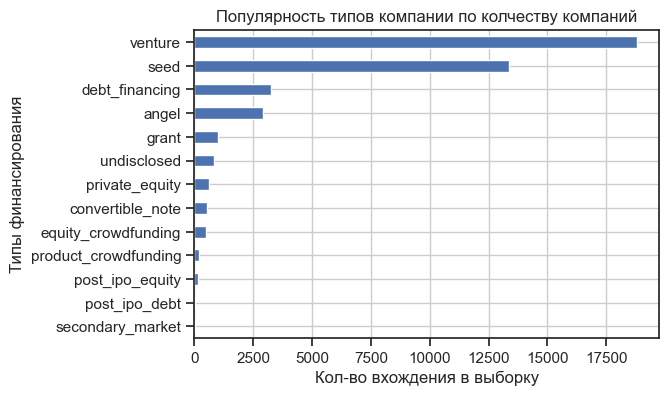

In [ ]:

popularity = (df[funding_types] > 0).sum().sort_values(ascending=False)
print(popularity)

plt.figure(figsize=(6,4))

popularity.sort_values(ascending=True).plot(
    kind='barh',
    title = 'Популярность типов компании по колчеству компаний',
)

plt.grid()
plt.ylabel('Типы финансирования')
plt.xlabel('Кол-во вхождения в выборку')
plt.show()

Постройте график суммарных объёмов возвратов от разных типов финансирования за весь период на основе дополнительного датасета.

In [ ]:
## Значения для вывода о том, как соотносится сумма финансированию по его популярности

avg_funding = amount / popularity
avg_funding_sorted = avg_funding.sort_values(ascending=False)
print(avg_funding_sorted)

post_ipo_equity        11868610
post_ipo_debt          10619198
private_equity          7638972
venture                 6859310
secondary_market        6469399
undisclosed             2583459
debt_financing          2504794
grant                   1972930
convertible_note        1086448
product_crowdfunding     912225
angel                    844829
seed                     705146
equity_crowdfunding      462060
dtype: float64


venture                40578620000
debt_financing          4734850000
private_equity          3587330000
seed                    2382240000
angel                   1509230000
post_ipo_equity         1104960000
undisclosed              730880000
post_ipo_debt             91030000
convertible_note          34790000
secondary_market           5200000
equity_crowdfunding        3830000
product_crowdfunding       1860000
grant                            0
dtype: float64


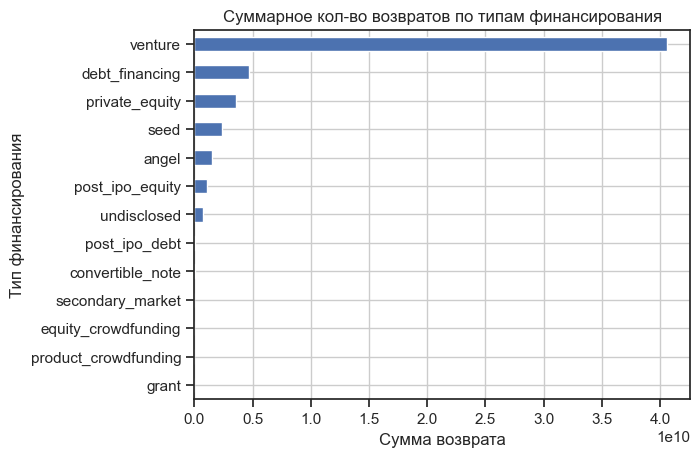

In [ ]:

data = readRet[funding_types].sum()*(10**6)

print(data.sort_values(ascending=False))
data.sort_values().plot(
    kind='barh',
    title='Суммарное кол-во возвратов по типам финансирования',
    grid=True
)

plt.xlabel('Сумма возврата')
plt.ylabel('Тип финансирования')
plt.show()

### Итоговый вывод по типам финансирования

По графикам и результатам анализа можно сделать следующие выводы:

**Сумма инвестиций и количество участий:**
1. **`venture`** имеет **наибольшую сумму инвестиций** и **наибольшее количество участий** в инвестициях;
2. **`secondary_market`** имеет **наименьшую сумму инвестиций** и `equity_crowdfunding` имеет **наименьшее количество участий** в инвестициях.

**Соотношение суммы инвестиций и количества участий:**
- **`post_ipo_equity`** — является **редким типом** с значительными объёмом финанрсирования.
- **`equity_crowdfunding`** — является **часто используемым типов** с небольшими объёмомами финанрсирования.

**Возвраты инвестиций:**
По графику также заметно, что **наибольшее количество возвратов** было произведено по типу финансирования **`venture`**, а **наименьшее** — по типу **`grant`**.

## Шаг 4. Анализ динамики

### 4.1 Динамика предоставления финансирования по годам

Используя столбцы `funding_total_usd` и `funding_rounds`, рассчитайте для каждой компании средний объём одного раунда финансирования.

На основе получившейся таблицы постройте графики, отражающие:
* динамику типичного размера средств, которые стартапы получали в рамках одного раунда финансирования;

* динамику общего количества раундов за каждый год, то есть насколько активно происходили инвестиции на рынке (чем больше раундов, тем выше активность).

Когда будете строить графики в этом задании и следующих, используйте данные только по тем компаниям, которые остались в датасете после предыдущих фильтраций.

На основе полученных данных ответьте на вопросы:
* В каком году типичный размер средств, собранных в рамках одного раунда, был максимальным?

* Какая тенденция наблюдалась в 2014 году по количеству раундов и средств, выделяемых в рамках каждого раунда?

In [ ]:
data = df.groupby(['name', 'funding_year']).agg(
    total_sum = ('funding_total_usd','sum'),
    count_rounds = ('funding_rounds', 'sum')
)

data['avg']= data['total_sum']/data['count_rounds']

yearly= data.groupby('funding_year')['avg'].agg(median='median', count='count').reset_index()

print(yearly.sort_values(by='median',ascending=False))

    funding_year  median  count
5           2005 4500000    697
6           2006 3900000   1165
2           2002 3225000     48
4           2004 3000000     96
7           2007 2884301   1596
0           2000 2250000     65
8           2008 2175000   1981
1           2001 1570886     37
3           2003 1500000     63
9           2009 1500000   2615
10          2010 1250000   3463
11          2011  867597   4303
12          2012  686000   5530
14          2014  561238   6075
13          2013  560000   7814


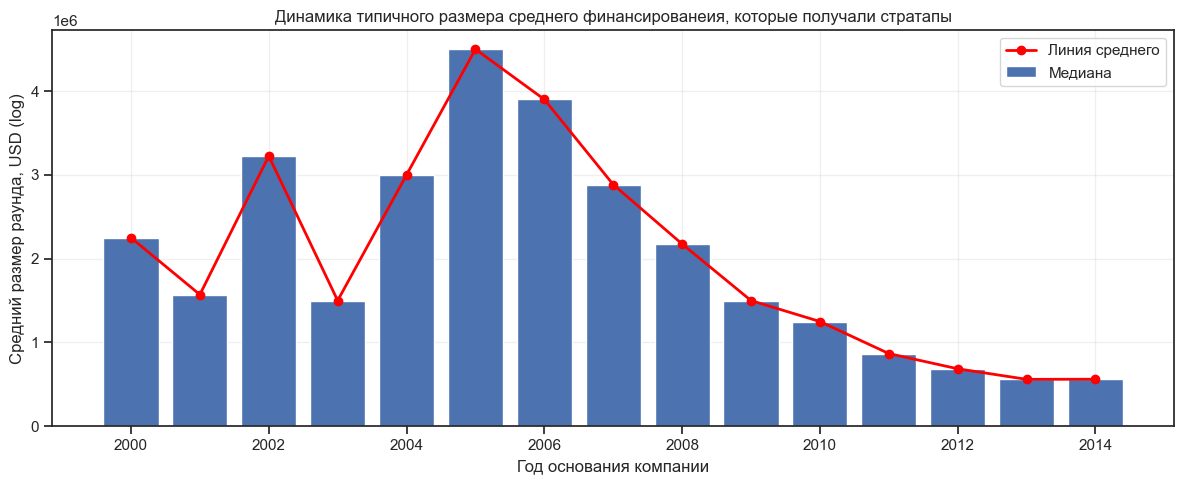

In [ ]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.bar(yearly['funding_year'], yearly['median'], label='Медиана')
ax.plot(yearly['funding_year'], yearly['median'], color='red', marker='o', linewidth=2, label='Линия среднего')
             
ax.set_xlabel('Год основания компании')
ax.set_ylabel('Средний размер раунда, USD (log)')
ax.set_title('Динамика типичного размера среднего финансированеия, которые получали стратапы')
ax.grid(alpha=0.3, which='both')
ax.legend()
plt.tight_layout()
plt.show()

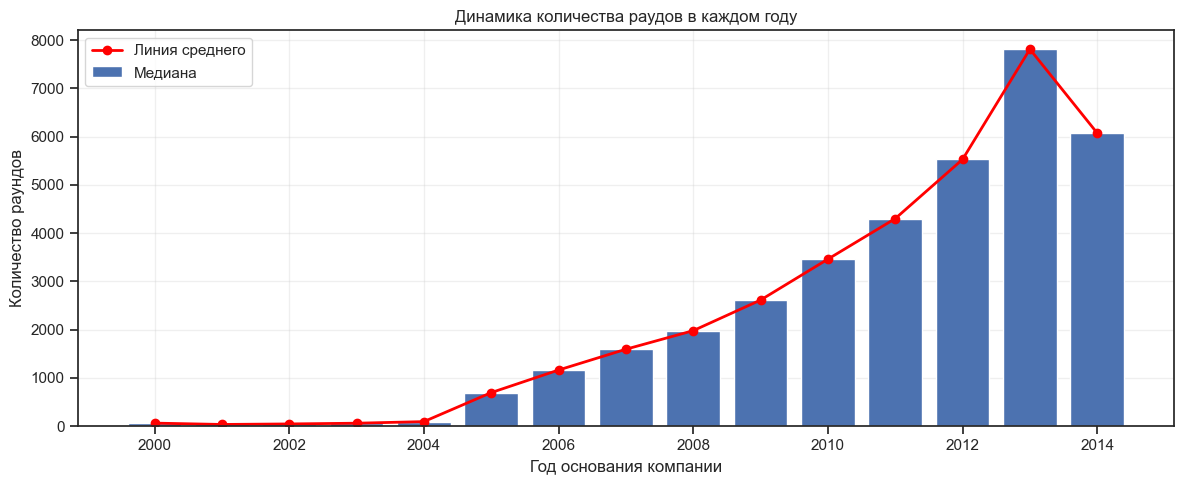

In [ ]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.bar(yearly['funding_year'], yearly['count'], label='Медиана')
ax.plot(yearly['funding_year'], yearly['count'], color='red', marker='o', linewidth=2, label='Линия среднего')
              
ax.set_xlabel('Год основания компании')
ax.set_ylabel('Количество раундов')
ax.set_title('Динамика количества раудов в каждом году')
ax.grid(alpha=0.3, which='both')
ax.legend()
plt.tight_layout()
plt.show()

### Ответы на исследовательские вопросы

Пик «дорогих» раундов пришелся на докризисный 2005 год. В последующие годы рынок стал более демократичным по количеству сделок, но стоимость входа в одну компанию в среднем сильно упала. Данные за 2014 год демонстрируют аномальное падение активности, что требует проверки на полноту данных за этот год.

### 4.2 Динамика размера общего финансирования по массовым сегментам рынка для растущих в 2014 году сегментов

Составьте сводную таблицу, в которой указывается суммарный размер общего финансирования `funding_total_usd` по годам и сегментам рынка. Отберите из неё только те сегменты, которые показывали рост размера суммарного финансирования в 2014 году по сравнению с 2013.

На графике отразите, как менялся суммарный размер общего финансирования в каждом из отобранных сегментов по годам, за которые у вас достаточно данных. Рассматривайте только массовые сегменты, а средние и нишевые исключите.

На основе графика сделайте вывод о том, какие сегменты показывают наиболее быстрый и уверенный рост.

In [ ]:
data = df[(df['market'] != 'mid') & (df['market'] != 'niche')]

pivot = pd.pivot_table(
    data,
    values='funding_total_usd',
    index='funding_year',           
    columns='market',
    aggfunc='sum',
    fill_value=0
).sort_index()

mask = pivot.loc[2014] > pivot.loc[2013]
selected = pivot[mask[mask].index]
display(selected)

market,Apps,BigData,Design,Internet,Manufacturing,Medical,RealEstate,SaaS,Startups,Technology,unknown
funding_year,,,,,,,,,,,
2000,0,0,0,10000000,56659310,24000000,2500000,0,0,0,1839560
2001,0,0,0,0,2368582,0,0,0,0,22160000,10160345
2002,0,0,0,1100000,0,0,5275000,2000000,0,11000000,242132
2003,0,0,0,0,4269608,0,6292200,0,0,0,4155202
2004,0,0,0,10500000,3000000,0,0,0,0,1750000,10847977
2005,0,0,9300000,1775000,61770000,11090000,250000,5240000,0,50728425,28384331
2006,1310600,0,707000,5000,163957751,20250000,2080000,4791121,0,22791000,46049840
2007,0,7780000,10800000,4495379,147726051,2100000,33220000,14652595,0,180190209,35532468
2008,4300000,2452515,5944302,23412964,173054260,28812744,46613100,27226900,5010387,277726238,45345010


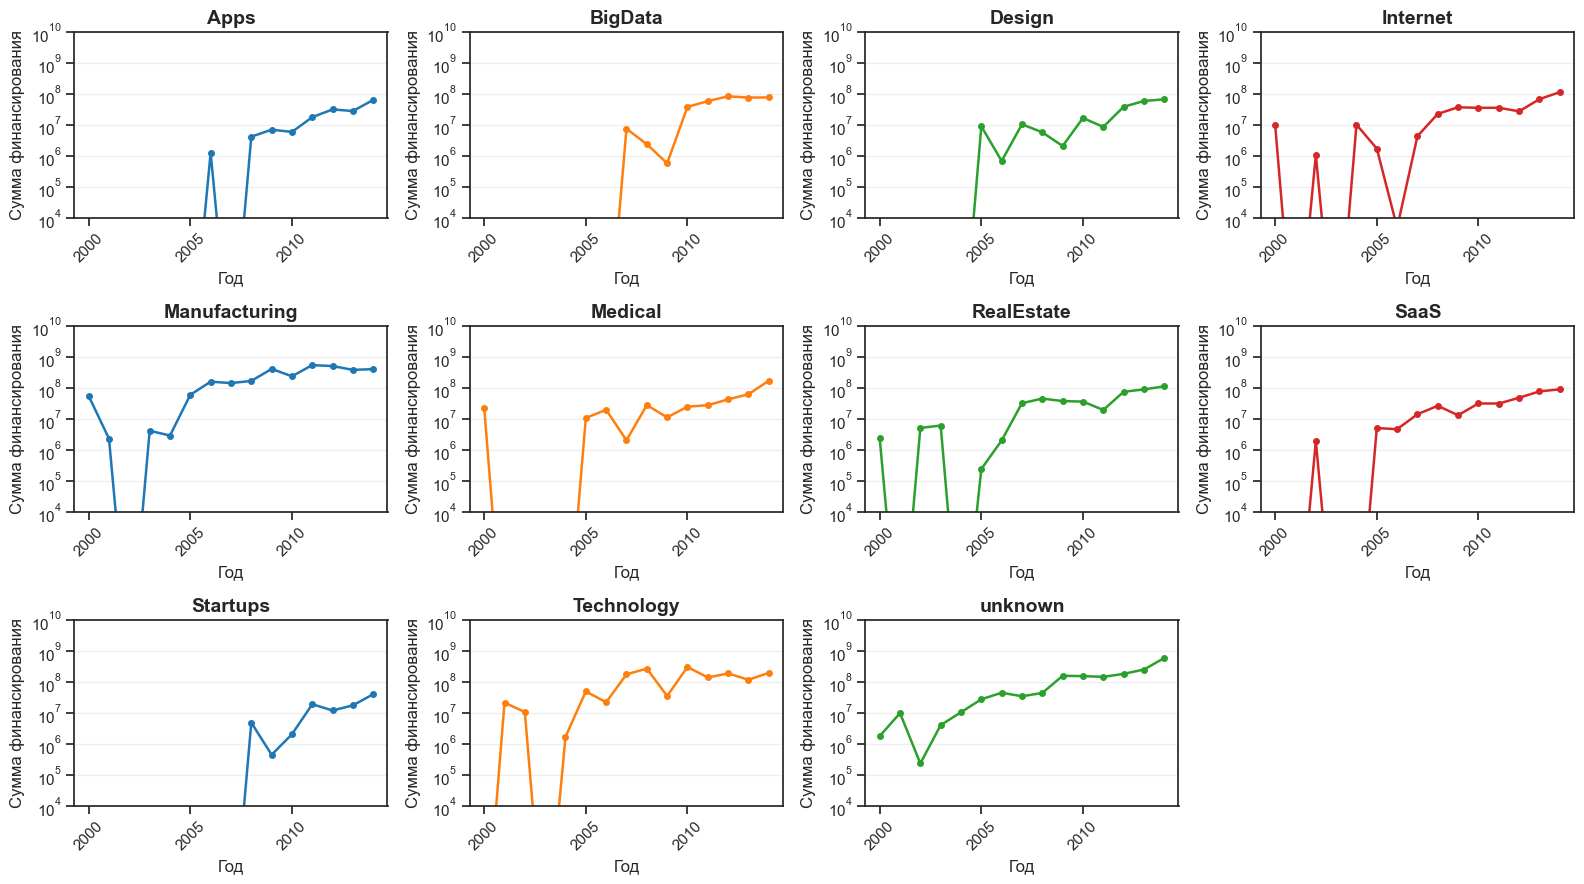

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

cols = selected.columns[:12]
years = selected.index

fig, axes = plt.subplots(3, 4, figsize=(16, 9), squeeze=False)
axes = axes.flatten()

colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']

Y_MAX = 10**10
Y_MIN = 10**4

for i, col in enumerate(cols):
    ax = axes[i]
    ax.plot(years, selected[col],
            color=colors[i % len(colors)],
            marker='o', markersize=4,
            linewidth=1.8)

    ax.set_title(col, fontsize=14, fontweight='bold')
    ax.set_xlabel('Год')
    ax.set_ylabel('Сумма финансирования')
    ax.grid(alpha=0.3, which='both', axis='y')
    ax.tick_params(axis='x', rotation=45)

    ax.set_yscale('symlog')
    ax.set_ylim(Y_MIN, Y_MAX)

for j in range(len(cols), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

In [ ]:


df1 = df[df['market'] != 'unknown'].copy() 
df1['mid_funding_year'] = df1['mid_funding_at'].dt.year


market_year_usd = (
    df1.pivot_table(
        index='market',
        columns='mid_funding_year',
        values='funding_total_usd',
        aggfunc='sum'
    )
    .fillna(0)
    .drop(['mid', 'niche'], errors='ignore')
)

market_year_usd_up = market_year_usd[
    market_year_usd[2014] > market_year_usd[2013]
]

plot_df = (
    market_year_usd_up
    .reset_index()
    .melt(id_vars='market', var_name='year', value_name='funding_total_usd')
)

fig = px.line(
    plot_df,
    x='year',
    y='funding_total_usd',
    color='market',
    markers=True,
    title='Динамика суммарного финансирования по растущим массовым сегментам',
    labels={
        'year': 'Год',
        'funding_total_usd': 'Суммарное финансирование, USD',
        'market': 'Сегмент рынка'
    }
)

fig.update_layout(
    template='plotly_white',
    legend_title_text='Сегмент',
    hovermode='closest',  
    width=800,
    height=600,
    legend=dict(
        title_text='Сегмент',
        font=dict(size=16),           
        title_font=dict(size=17),     
    )
)

fig.show()

### Вывод по динамике сегментов (2013–2014)

Судя по графикам сегментов, у которых значения за 2013 год ниже, чем за 2014, можно заметить следующие тенденции:

- Активно стала развиваться среда **`Manufacturing`**;
- Сегмент **`Medical`** в целом имеет хорошие показатели, и более стабилен;

### 4.3 Годовая динамика доли возвращённых средств по типам финансирования

Заказчик хочет знать, какая часть вложенных или выданных денег со временем возвращается обратно инвесторам или финансистам. Ваша цель — для каждого года и каждого вида финансирования рассчитать нормированные значения возврата средств: то есть какую долю возвращённые средства составляют от предоставленных. При этом слишком большие аномальные значения, то есть неадекватные выбросы, нужно заменить на пропуски.

Совет: когда будете делить сумму возвращённых средств на суммарный объём привлечённого финансирования по конкретному году, добавьте к знаменателю небольшое число, например `1e-60`. Это поможет избежать деления на ноль.

In [ ]:
funding_types = [
    'seed', 'venture', 'equity_crowdfunding', 'undisclosed',
    'convertible_note', 'debt_financing', 'angel', 'grant',
    'private_equity', 'post_ipo_equity', 'post_ipo_debt',
    'secondary_market', 'product_crowdfunding'
]

df = df.rename(columns={'funding_year': 'year'})

invest = df.groupby('year')[funding_types].sum()
back   = readRet.groupby('year')[funding_types].sum()

ratio = back / (invest*10**6 + 1e-60)

flat = ratio.stack()
Q1, Q3 = flat.quantile(0.25), flat.quantile(0.75)
upper = Q3 + 1.5* (Q3 - Q1) ###

ratio = ratio.mask(ratio > upper)


Постройте график, на котором отобразите нормированные значения возврата средств для типов финансирования `venture`, `debt_financing`, `private_equity`, `seed` и `angel`.

Сделайте вывод о том, в каких типах финансирования наблюдается наиболее устойчивый рост показателя.

In [542]:
plot_df = ratio.reset_index().melt(
    id_vars=ratio.index.name if ratio.index.name else 'index', 
    value_vars=['venture', 'debt_financing', 'private_equity', 'seed', 'angel'],
    var_name='funding_type',
    value_name='normalized_return'
)

# Интерактивный график
fig = px.line(
    plot_df,
    x=plot_df.columns[0],  
    y='normalized_return',
    color='funding_type',
    markers=True,
    title='Возврат средств по типам финансирования',
    labels={
        plot_df.columns[0]: 'Год',
        'normalized_return': 'Нормированный возврат',
        'funding_type': 'Тип финансирования'
    }
)

fig.update_layout(
    template='plotly_white',
    legend_title_text='Тип финансирования',
    hovermode='closest',  
    width=800,
    height=600,
    legend=dict(
        title_text='Тип финансирования',
        font=dict(size=16),           
        title_font=dict(size=17),     
    )
)

fig.show()

### Вывод по динамике возвратов инвестиций

По графику видно, что ближе к правой части график **начинают увеличиваться**. Это объясняется тем, что стартапы «созревают» и начинают возвращать вложенные средства.

Среди типов финансирования **самым плавно растущим** является **private_equity** — его график демонстрирует наиболее стабильную восходящую динамику без резких провалов, и к 2014 году он показывает одни из лучших результатов.


## Шаг 5. Итоговый вывод и рекомендации

Представьте, что на календаре 2015 год. Опираясь на результаты анализа, дайте рекомендацию заказчику:

* в какую отрасль стоит инвестировать;
* какой тип финансирования при этом будет наиболее уместным.

Подведите итоги проекта:
* опишите, какие шаги были выполнены;
* какие выводы удалось сделать;
* насколько выводы согласуются между собой или, наоборот, вызывают сомнения.




### Рекомендации по выбору отрасли и типа финансирования

Опираясь на выводы, полученные в ходе анализа, можно сформулировать следующие рекомендации:

**По выбору отрасли:**
- **`Hospitality`** — перспективное направление. Отрасль относительно новая и демонстрирует тренд на повышение, что делает её привлекательной для вложений.
- **`Software`** — надёжное и стабильное направление. За годы существования отрасль не показывала сильных падений, но и не росла резко, что говорит о её стабильности.

**По выбору типа финансирования:**
- Лучше выбрать **`venture`** или **`debt_financing`**. Однако **`venture`** выглядит предпочтительнее: им пользуется большинство инвесторов, и возвраты по этому типу наиболее стабильны.

## Итоговый вывод

В ходе исследования данные были очищены, размечены по сегментам рынка и проверены на аномалии. Из **54 294 строк** в анализ вошло **40 907 компаний** (75,3\% исходного объёма).

### Шаг 1–2. Предобработка и инжиниринг
- Удалены **4 856** полностью пустых строк и **8 531** строка без суммы финансирования. Восстановлено **13 675** из **13 676** пропусков в `mid_funding_at` — как середина между первым и последним раундом.
- Оставшиеся пропуски неустранимы: дата основания отсутствует у **21\%** компаний, `participants` — у **33\%**, `region` и `city` — у **9–11\%**.
- **Главная диспропорция рынка — в сроке финансирования:** 58,9\% компаний привлекли деньги один раз, но получили лишь 30,6\% всех средств, тогда как 30,1\% компаний со сроком более года собрали 62,9\% денег. Объём создают не многочисленные разовые сделки, а длительные отношения с инвесторами.
- **Всего сегментов 395:** 289 нишевых, 57 средних, 49 массовых. В массовых сосредоточено **36,2 тыс.** компаний, в средних — 3,8 тыс., в нишевых — 0,8 тыс. Аномальным признано финансирование у **5 244** компаний (12,8\%), причём по доле аномалий сегменты почти не различаются (15,9–17,2\%) — «выбросность» задаётся не отраслью, а размером сделки.

### Шаг 3. Анализ типов финансирования
- **`venture` — единственный инструмент, который одновременно массовый, крупный и возвратный:** 345,5 млрд \$ (57,3\% объёма), 21 943 компании (58\%), 40,6 млрд \$ возвратов, средний чек 15,8 млн \$.
- **Обратный полюс — `seed`:** второе место по числу компаний (12 597), но средний чек 0,77 млн \$ и лишь 1,6\% объёма. `angel` устроен похоже: 2 844 компании при чеке 1,0 млн \$.
- **Редко, но дорого — инструменты единичных крупных размещений:** `post_ipo_debt` и `secondary_market`.

### Шаг 4. Динамика финансирования и возвратов
- **Рынок рос вширь, а не вглубь:** число раундов выросло с 66 в 2001 году до 13 292 в 2013-м, тогда как медианный размер раунда упал с 6,04 млн \$ (2004) до 0,72 млн \$ (2013). Денег в разы больше, но каждый чек мельче.
- **2014 год — не обвал, а консолидация:** раундов 6 699 против 13 292 (вдвое меньше), объём 65,8 млрд \$ (−9,8\% к 2013), но медианный чек вырос на 5,6\% до 762 тыс. \$. Сделок меньше, и они крупнее.
- **Быстрее всего в 2014 году росли:** `Manufacturing` (самый высокий пик и абсолютный лидер по объёму), `Medical` (показывают уверенный и стабильный рост).
- **Отдача растёт и концентрируется в `debt_financing` и `private_equity`:** в целом по рынку возвраты составляют 9,1\% вложенного. Даёт `private_equity` — наиболее стабильную восходящую динамику. `venture` и `seed` к концу периода остаются на низком уровне.

### Главный итог
Выводы согласуются между собой по трём независимым срезам — по объёму, по числу компаний и по возвратам: **`venture` доминирует во всех трёх**, а рынок последних лет растёт числом сделок при падении их размера.

Единственное расхождение — «спад» 2014 года по раундам плохо согласуется с ростом крупнейших сегментов и всплеском возвратов. Вероятная причина в том, что год привязан к середине периода финансирования (`mid_funding_at`), из-за чего компании с поздними раундами попадают в более ранние годы.